Mode: COLOR (BGR, per-channel filtering)
Processing sky (512, 384, 3) ...


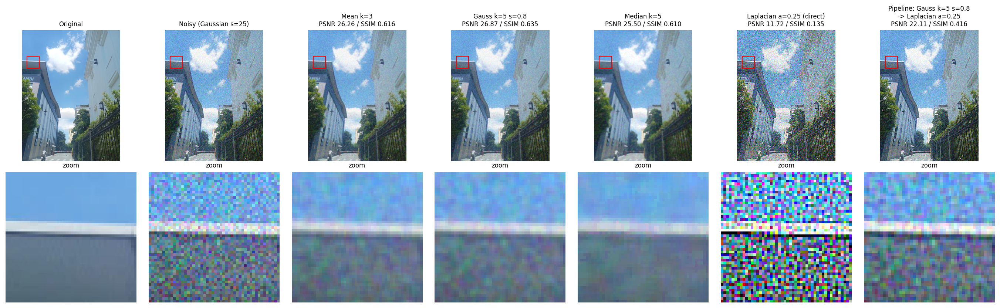

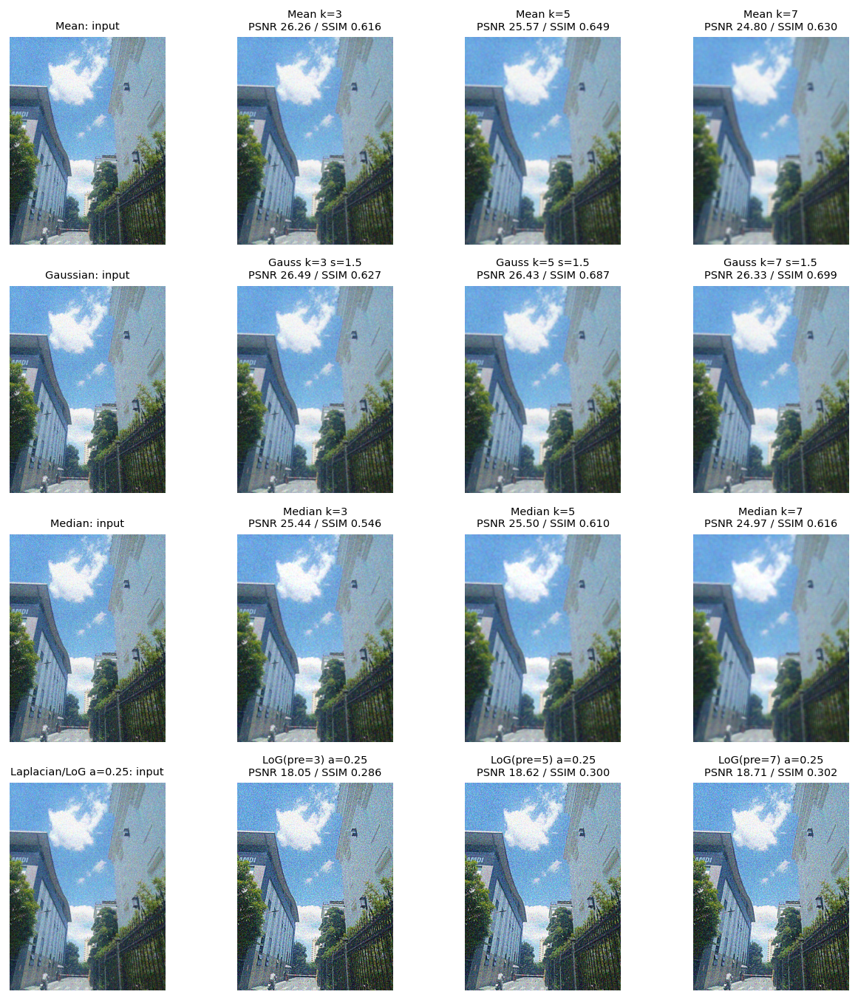

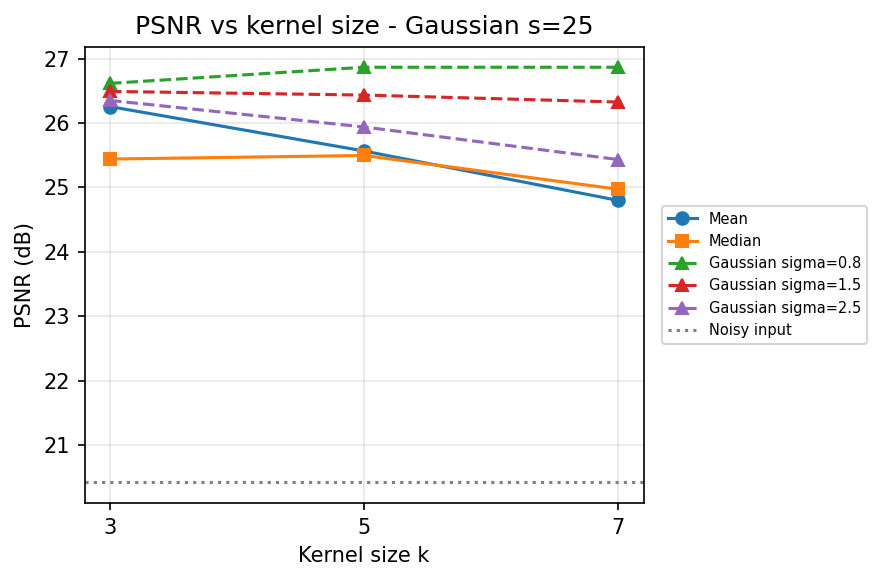

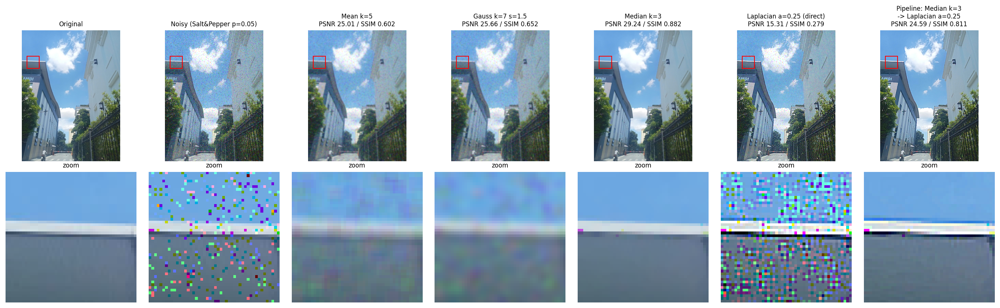

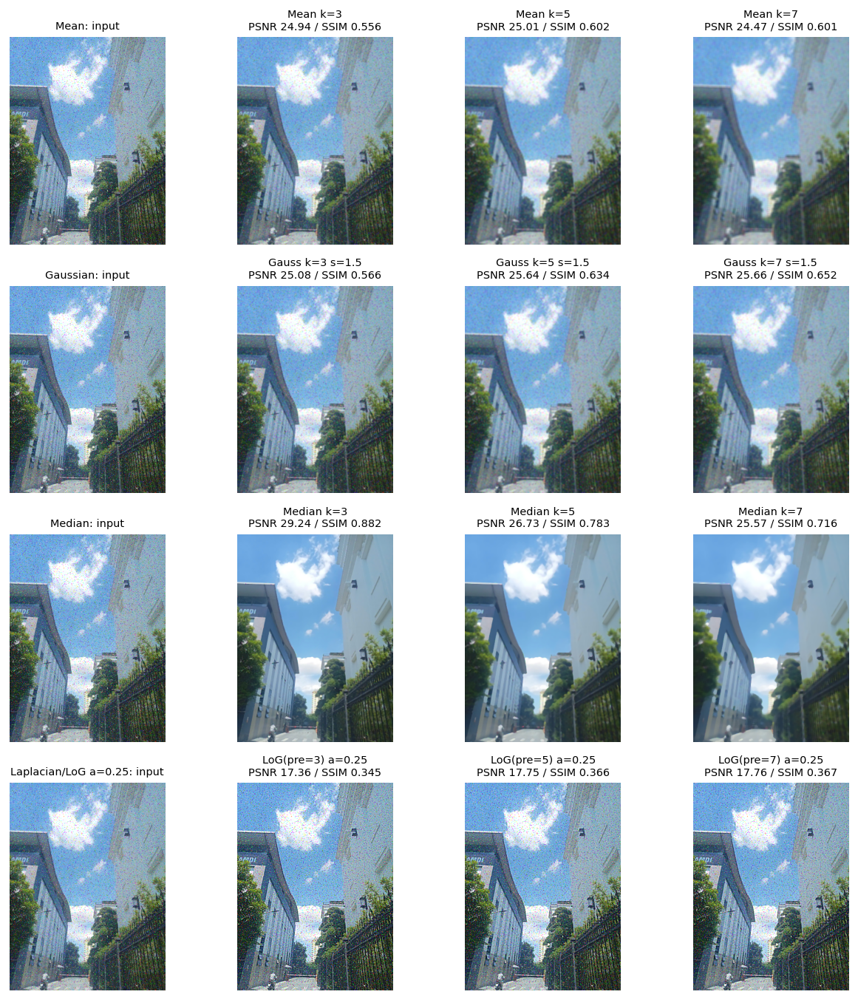

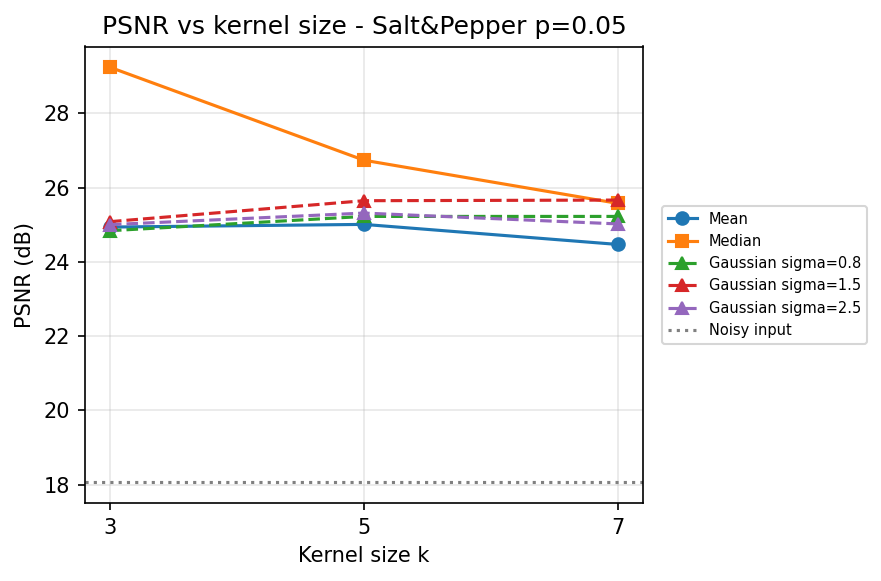

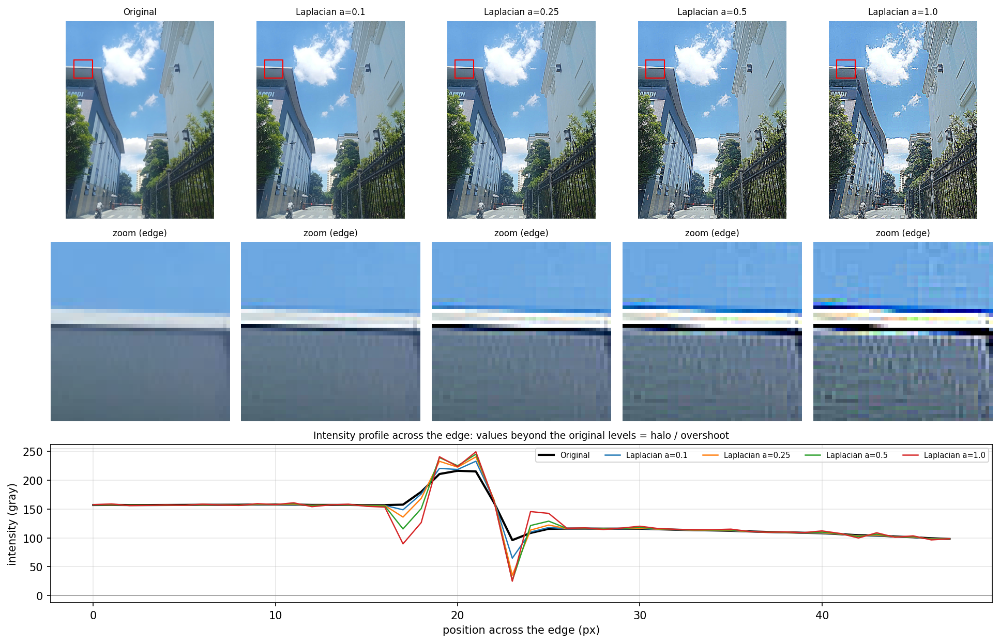

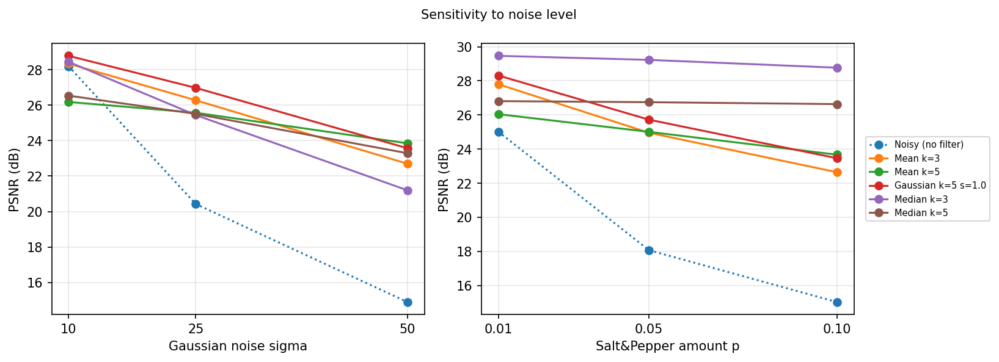


Best setting per filter family (by PSNR):


,image,noise,filter,params,psnr,ssim,mse,time_ms
0,sky,clean,Laplacian sharpen,"preblur=7, alpha=0.1",39.888,0.992,6.672,3.622
1,sky,gaussian,Gaussian,"k=5, sigma=0.8",26.866,0.635,133.801,0.067
2,sky,gaussian,Mean,k=3,26.256,0.616,153.986,0.394
3,sky,gaussian,Median,k=5,25.496,0.610,183.415,1.632
4,sky,gaussian,Pipeline (best denoise -> Laplacian),Gauss k=5 s=0.8 -> alpha=0.25,22.106,0.416,400.428,3.251
5,sky,gaussian,Laplacian sharpen,"preblur=7, alpha=0.1",19.750,0.323,688.827,4.206
6,sky,salt_pepper,Median,k=3,29.237,0.882,77.518,0.103
7,sky,salt_pepper,Gaussian,"k=7, sigma=1.5",25.662,0.652,176.560,0.080
8,sky,salt_pepper,Mean,k=5,25.007,0.602,205.296,0.477
9,sky,salt_pepper,Pipeline (best denoise -> Laplacian),Median k=3 -> alpha=0.25,24.586,0.811,226.180,4.390



Done. Results saved in x:\Vision\results\partA


In [2]:
"""
INS3155 - Midterm Project - Part A: Image Filtering and Enhancement
-------------------------------------------------------------------
Pipeline:
  1. Load clean grayscale images from data/partA/ (fallback: skimage 'camera').
     (grayscale by default; colour with --color or USE_COLOR = True)
  2. Synthesize noise: Gaussian and Salt-and-Pepper (fixed seed -> reproducible).
  3. Apply 4 spatial filters with several kernel sizes / parameters:
       Mean (box), Gaussian (several sigma), Median, Laplacian sharpening.
  4. Evaluate vs. the CLEAN image: MSE, PSNR (dB), SSIM, execution time (ms).
  5. Save: metrics CSV, side-by-side grids, kernel-sweep grids, PSNR plots.

Run from the project root:
    python src/partA_filtering.py
    python src/partA_filtering.py --max-size 512 --repeats 20 --sensitivity
"""
import argparse
import sys
import time
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib
IN_NOTEBOOK = "ipykernel" in sys.modules      # True when run in Jupyter / VS Code cell
if not IN_NOTEBOOK:
    matplotlib.use("Agg")                      # terminal: save files only, no window
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity

# ----------------------------- Configuration -------------------------------
SEED = 42
KERNELS = [3, 5, 7]            # kernel sizes for Mean / Gaussian / Median
GAUSS_SIGMAS = [0.8, 1.5, 2.5]  # sigma values for the Gaussian filter
SHARP_MAIN = 0.25             # alpha used in the summary grids, kernel sweep and pipeline
SHARP_PREBLUR = [0, 3, 5, 7]   # Gaussian pre-blur size before Laplacian (0 = none)
SHARP_ALPHAS = [0.1, 0.25, 0.5, 1.0]  # sharpening strength alpha.
                               # NOTE: with the Laplacian centre = -4,  I - a*lap = I + 4a*(I - mean of 4 neighbours)
                               # so a = 1.0 is exactly the lecture kernel [[0,-1,0],[-1,5,-1],[0,-1,0]] (strong!)
SHARP_SIGMA = 1.0              # sigma of the pre-blur (LoG)
NOISE_GAUSS_SIGMA = 25         # std of additive Gaussian noise (gray levels)
NOISE_SP_AMOUNT = 0.05         # total fraction of salt + pepper pixels
USE_COLOR = True               # True -> process BGR colour images (each channel filtered)
                               # can also be set from terminal with:  --color

ZOOM_SIZE = 48                 # side (px) of the zoom window
ZOOM_REGION = {"sky": (100, 20)}  # image name -> (row, col) of the zoom window, put it on a SHARP EDGE.
                               # Images not listed here use an automatic choice.
SENSITIVITY = True            # True -> also run the noise-level study (or use --sensitivity)
SENS_GAUSS_SIGMAS = [10, 25, 50]
SENS_SP_AMOUNTS = [0.01, 0.05, 0.10]

try:
    ROOT = Path(__file__).resolve().parent.parent      # run as: python src/partA_filtering.py
except NameError:                                       # run inside Jupyter / VS Code cell
    ROOT = Path.cwd().parent if Path.cwd().name == "src" else Path.cwd()
DATA_DIR = ROOT / "data" / "partA"
OUT_DIR = ROOT / "results" / "partA"


# ------------------------------- Noise models ------------------------------
def add_gaussian_noise(img, sigma, rng):
    """I_noisy = clip(I + n), n ~ N(0, sigma^2)."""
    noise = rng.normal(0.0, sigma, img.shape)
    return np.clip(img.astype(np.float64) + noise, 0, 255).astype(np.uint8)


def add_salt_pepper_noise(img, amount, rng):
    """Pixel -> 0 with prob amount/2 (pepper), -> 255 with prob amount/2 (salt)."""
    out = img.copy()
    r = rng.random(img.shape)
    out[r < amount / 2] = 0
    out[r > 1 - amount / 2] = 255
    return out


# --------------------------------- Filters ---------------------------------
def mean_filter(img, k):
    return cv2.blur(img, (k, k))


def gaussian_filter(img, k, sigma):
    return cv2.GaussianBlur(img, (k, k), sigma)


def median_filter(img, k):
    return cv2.medianBlur(img, k)


def laplacian_sharpen(img, preblur, alpha, sigma=SHARP_SIGMA):
    """I_sharp = I - alpha * Lap(G_sigma * I)   (kernel centre = -4).
    preblur = 0 -> plain Laplacian; preblur > 0 -> Laplacian of Gaussian (LoG).
    Computed in float64 (keeps negative values), then clipped to [0, 255]."""
    src = img if preblur == 0 else cv2.GaussianBlur(img, (preblur, preblur), sigma)
    lap = cv2.Laplacian(src, cv2.CV_64F, ksize=3)
    out = img.astype(np.float64) - alpha * lap
    return np.clip(out, 0, 255).astype(np.uint8)


# --------------------------------- Metrics ---------------------------------
def evaluate(ref, out):
    diff = ref.astype(np.float64) - out.astype(np.float64)
    mse = float(np.mean(diff ** 2))
    psnr = float("inf") if mse == 0 else 10 * np.log10(255.0 ** 2 / mse)
    ssim = float(structural_similarity(ref, out, data_range=255,
                                       channel_axis=2 if ref.ndim == 3 else None))
    return mse, psnr, ssim


def timed(fn, repeats):
    """Run fn() `repeats` times, return (result, median time in ms)."""
    times, res = [], fn()                 # first call = warm-up (not timed)
    for _ in range(repeats):
        t0 = time.perf_counter()
        res = fn()
        times.append((time.perf_counter() - t0) * 1000)
    return res, float(np.median(times))


# ------------------------------ Experiment list ----------------------------
def build_filter_configs():
    """Return list of (family, label, params-string, function(img) -> img)."""
    cfgs = []
    for k in KERNELS:
        cfgs.append(("Mean", f"Mean k={k}", f"k={k}",
                     lambda im, k=k: mean_filter(im, k)))
    for k in KERNELS:
        for s in GAUSS_SIGMAS:
            cfgs.append(("Gaussian", f"Gauss k={k} s={s}", f"k={k}, sigma={s}",
                         lambda im, k=k, s=s: gaussian_filter(im, k, s)))
    for k in KERNELS:
        cfgs.append(("Median", f"Median k={k}", f"k={k}",
                     lambda im, k=k: median_filter(im, k)))
    for pb in SHARP_PREBLUR:
        for a in SHARP_ALPHAS:
            tag = "Laplacian" if pb == 0 else f"LoG(pre={pb})"
            cfgs.append(("Laplacian sharpen", f"{tag} a={a}",
                         f"preblur={pb}, alpha={a}",
                         lambda im, pb=pb, a=a: laplacian_sharpen(im, pb, a)))
    return cfgs


# --------------------------------- Plotting --------------------------------
def find_edge_region(img, size=48):
    """Top-left corner of the size x size window with the strongest edges."""
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) if img.ndim == 3 else img
    gx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
    mag = cv2.GaussianBlur(np.hypot(gx, gy), (0, 0), size / 4)
    r, c = np.unravel_index(np.argmax(mag), mag.shape)
    r = int(np.clip(r - size // 2, 0, img.shape[0] - size))
    c = int(np.clip(c - size // 2, 0, img.shape[1] - size))
    return r, c


def save_fig(fig, path, dpi):
    """Save the figure; in a notebook also display it below the cell."""
    fig.savefig(path, dpi=dpi, bbox_inches="tight")
    plt.close(fig)
    if IN_NOTEBOOK:                      # show the saved PNG: works with any backend
        try:
            from IPython.display import Image, display
            display(Image(filename=str(path)))
        except ImportError:
            pass


def get_zoom(name, img):
    """(row, col, size) of the zoom window: manual (ZOOM_REGION) or automatic."""
    s = ZOOM_SIZE
    if name in ZOOM_REGION:
        r, c = ZOOM_REGION[name]
        r = int(np.clip(r, 0, img.shape[0] - s))
        c = int(np.clip(c, 0, img.shape[1] - s))
    else:
        r, c = find_edge_region(img, s)
    return r, c, s


def show(ax, img, title):
    if img.ndim == 3:                                  # colour (OpenCV BGR -> RGB)
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    else:
        ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title, fontsize=8)
    ax.axis("off")


def plot_summary_grid(path, clean, noisy, picks, noise_label, zoom):
    """Row 1: full images. Row 2: zoom on the chosen edge region."""
    r, c, s = zoom
    items = [("Original", clean), (f"Noisy ({noise_label})", noisy)] + picks
    fig, axes = plt.subplots(2, len(items), figsize=(2.6 * len(items), 5.6))
    for j, (title, im) in enumerate(items):
        show(axes[0, j], im, title)
        axes[0, j].add_patch(plt.Rectangle((c, r), s, s, fill=False,
                                           ec="red", lw=1))
        show(axes[1, j], im[r:r + s, c:c + s], "zoom")
    fig.tight_layout()
    save_fig(fig, path, 150)


def plot_kernel_sweep(path, noisy, outputs):
    """Rows = filters, cols = noisy input + 3 kernel settings."""
    rows = [
        ("Mean", [f"Mean k={k}" for k in KERNELS]),
        ("Gaussian", [f"Gauss k={k} s=1.5" for k in KERNELS]),
        ("Median", [f"Median k={k}" for k in KERNELS]),
        (f"Laplacian/LoG a={SHARP_MAIN}",
         [f"LoG(pre={pb}) a={SHARP_MAIN}" for pb in SHARP_PREBLUR[1:]]),
    ]
    fig, axes = plt.subplots(len(rows), 4, figsize=(10, 10.5))
    for i, (name, labels) in enumerate(rows):
        show(axes[i, 0], noisy, f"{name}: input")
        for j, lab in enumerate(labels):
            if lab in outputs:
                show(axes[i, j + 1], outputs[lab][0], f"{lab}\n"
                     f"PSNR {outputs[lab][1]:.2f} / SSIM {outputs[lab][2]:.3f}")
            else:  # label not computed (e.g. sigma not in list)
                axes[i, j + 1].axis("off")
    fig.tight_layout()
    save_fig(fig, path, 130)


def plot_psnr_curves(path, df_noise, noise_label):
    fig, ax = plt.subplots(figsize=(6, 4))
    for fam, mk in [("Mean", "o"), ("Median", "s")]:
        d = df_noise[df_noise["filter"] == fam].sort_values("kernel")
        ax.plot(d.kernel, d.psnr, marker=mk, label=fam)
    for s in GAUSS_SIGMAS:
        d = df_noise[(df_noise["filter"] == "Gaussian") & (df_noise.sigma == s)]
        ax.plot(d.kernel, d.psnr.values, marker="^", ls="--",
                label=f"Gaussian sigma={s}")
    ax.axhline(df_noise[df_noise["filter"] == "Noisy (no filter)"].psnr.iloc[0],
               color="gray", ls=":", label="Noisy input")
    ax.set_xticks(KERNELS)
    ax.set_xlabel("Kernel size k")
    ax.set_ylabel("PSNR (dB)")
    ax.set_title(f"PSNR vs kernel size - {noise_label}")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7, loc="center left", bbox_to_anchor=(1.02, 0.5))
    fig.tight_layout()
    save_fig(fig, path, 150)


def to_gray(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) if img.ndim == 3 else img


def plot_halo(path, clean, zoom):
    """Sharpen the CLEAN image with several alphas: full image, zoom on an edge,
    and the 1-D intensity profile across the edge (overshoot = halo / ringing)."""
    r, c, s = zoom
    items = [("Original", clean)] + [(f"Laplacian a={a}", laplacian_sharpen(clean, 0, a))
                                     for a in SHARP_ALPHAS]
    n = len(items)
    fig = plt.figure(figsize=(2.6 * n, 8.4))
    gs = fig.add_gridspec(3, n, height_ratios=[3, 3, 2.4])
    region = to_gray(clean)[r:r + s, c:c + s].astype(np.float64)
    along_x = np.abs(np.diff(region, axis=1)).sum() > np.abs(np.diff(region, axis=0)).sum()
    for j, (t, im) in enumerate(items):
        ax = fig.add_subplot(gs[0, j])
        show(ax, im, t)
        ax.add_patch(plt.Rectangle((c, r), s, s, fill=False, ec="red", lw=1))
        show(fig.add_subplot(gs[1, j]), im[r:r + s, c:c + s], "zoom (edge)")
    axp = fig.add_subplot(gs[2, :])
    for t, im in items:
        g = to_gray(im)[r:r + s, c:c + s].astype(np.float64)
        prof = g.mean(axis=0) if along_x else g.mean(axis=1)   # average along the edge
        axp.plot(prof, label=t, lw=2 if t == "Original" else 1.2,
                 color="k" if t == "Original" else None)
    axp.axhline(0, color="gray", lw=0.5)
    axp.axhline(255, color="gray", lw=0.5)
    axp.set_xlabel("position across the edge (px)")
    axp.set_ylabel("intensity (gray)")
    axp.set_title("Intensity profile across the edge: values beyond the original "
                  "levels = halo / overshoot", fontsize=9)
    axp.grid(alpha=0.3)
    axp.legend(fontsize=7, ncol=n)
    fig.tight_layout()
    save_fig(fig, path, 150)


def sensitivity_study(name, clean, out_dir):
    """Noise-level study: PSNR of a few filters vs noise strength."""
    rng = np.random.default_rng(SEED)
    flt = [("Mean k=3", lambda im: mean_filter(im, 3)),
           ("Mean k=5", lambda im: mean_filter(im, 5)),
           ("Gaussian k=5 s=1.0", lambda im: gaussian_filter(im, 5, 1.0)),
           ("Median k=3", lambda im: median_filter(im, 3)),
           ("Median k=5", lambda im: median_filter(im, 5))]
    rows = []
    for kind, levels in [("gaussian", SENS_GAUSS_SIGMAS), ("salt_pepper", SENS_SP_AMOUNTS)]:
        for lv in levels:
            noisy = (add_gaussian_noise(clean, lv, rng) if kind == "gaussian"
                     else add_salt_pepper_noise(clean, lv, rng))
            for lab, fn in [("Noisy (no filter)", lambda im: im)] + flt:
                mse, psnr, ssim = evaluate(clean, fn(noisy))
                rows.append(dict(image=name, noise=kind, level=lv, filter=lab,
                                 mse=mse, psnr=psnr, ssim=ssim))
    df = pd.DataFrame(rows)
    df.to_csv(out_dir / "sensitivity.csv", index=False, float_format="%.4f")
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for ax, (kind, xl) in zip(axes, [("gaussian", "Gaussian noise sigma"),
                                     ("salt_pepper", "Salt&Pepper amount p")]):
        d = df[df["noise"] == kind]
        for lab in d["filter"].unique():
            g = d[d["filter"] == lab].sort_values("level")
            ax.plot(g["level"], g["psnr"], marker="o", label=lab,
                    ls=":" if lab.startswith("Noisy") else "-")
        ax.set_xlabel(xl)
        ax.set_ylabel("PSNR (dB)")
        ax.set_xticks(sorted(d["level"].unique()))
        ax.grid(alpha=0.3)
    axes[1].legend(fontsize=7, loc="center left", bbox_to_anchor=(1.02, 0.5))
    fig.suptitle("Sensitivity to noise level", fontsize=10)
    fig.tight_layout()
    save_fig(fig, out_dir / "sensitivity_noise_level.png", 150)


# ---------------------------------- Main -----------------------------------
def load_images(max_size, color=False):
    paths = sorted(p for p in DATA_DIR.glob("*")
                   if p.suffix.lower() in {".png", ".jpg", ".jpeg", ".bmp", ".tif"})
    images = []
    for p in paths:
        im = cv2.imread(str(p), cv2.IMREAD_COLOR if color else cv2.IMREAD_GRAYSCALE)
        if im is None:
            continue
        images.append((p.stem, im))
    if not images:
        from skimage import data
        print("[!] No images in data/partA -> using skimage 'camera' as demo.")
        demo = data.astronaut()[:, :, ::-1].copy() if color else data.camera()
        images = [("camera_demo", demo)]
    out = []
    for name, im in images:
        h, w = im.shape[:2]
        if max(h, w) > max_size:
            f = max_size / max(h, w)
            im = cv2.resize(im, (int(w * f), int(h * f)), interpolation=cv2.INTER_AREA)
        out.append((name, im))
    return out


def process_image(name, clean, repeats, sens=False):
    rng = np.random.default_rng(SEED)
    zoom = get_zoom(name, clean)
    out_dir = OUT_DIR / name
    out_dir.mkdir(parents=True, exist_ok=True)
    noises = {
        "gaussian": (add_gaussian_noise(clean, NOISE_GAUSS_SIGMA, rng),
                     f"Gaussian s={NOISE_GAUSS_SIGMA}"),
        "salt_pepper": (add_salt_pepper_noise(clean, NOISE_SP_AMOUNT, rng),
                        f"Salt&Pepper p={NOISE_SP_AMOUNT}"),
    }
    cfgs = build_filter_configs()
    rows = []

    for nkey, (noisy, nlabel) in noises.items():
        cv2.imwrite(str(out_dir / f"noisy_{nkey}.png"), noisy)
        outputs = {}  # label -> (img, psnr, ssim)

        mse, psnr, ssim = evaluate(clean, noisy)
        rows.append(dict(image=name, noise=nkey, filter="Noisy (no filter)",
                         params="-", kernel=0, sigma=np.nan,
                         mse=mse, psnr=psnr, ssim=ssim, time_ms=0.0))

        for fam, label, params, fn in cfgs:
            res, t = timed(lambda: fn(noisy), repeats)
            mse, psnr, ssim = evaluate(clean, res)
            kernel = int(params.split("k=")[1].split(",")[0]) if fam != "Laplacian sharpen" \
                else int(params.split("preblur=")[1].split(",")[0])
            sigma = float(params.split("sigma=")[1]) if "sigma=" in params else np.nan
            rows.append(dict(image=name, noise=nkey, filter=fam, params=params,
                             kernel=kernel, sigma=sigma, mse=mse, psnr=psnr,
                             ssim=ssim, time_ms=t))
            outputs[label] = (res, psnr, ssim)

        df = pd.DataFrame([r for r in rows if r["noise"] == nkey])

        # best (by PSNR) setting of each denoising family + sharpening
        picks = []
        best_denoise = None
        for fam in ["Mean", "Gaussian", "Median"]:
            d = df[df["filter"] == fam].sort_values("psnr", ascending=False).iloc[0]
            lab = next(l for f, l, p, _ in cfgs if f == fam and p == d.params)
            picks.append((f"{lab}\nPSNR {d.psnr:.2f} / SSIM {d.ssim:.3f}", outputs[lab][0]))
            if best_denoise is None or d.psnr > best_denoise[1]:
                best_denoise = (fam, d.psnr, outputs[lab][0], lab)
        # sharpening applied directly on the noisy image
        lab = f"Laplacian a={SHARP_MAIN}"
        picks.append((f"{lab} (direct)\nPSNR {outputs[lab][1]:.2f} / SSIM {outputs[lab][2]:.3f}",
                      outputs[lab][0]))
        # pipeline: best denoiser -> Laplacian sharpen (answers 'denoise then sharpen')
        pipe, tp = timed(lambda: laplacian_sharpen(best_denoise[2], 0, SHARP_MAIN), repeats)
        mse, psnr, ssim = evaluate(clean, pipe)
        rows.append(dict(image=name, noise=nkey,
                         filter="Pipeline (best denoise -> Laplacian)",
                         params=f"{best_denoise[3]} -> alpha={SHARP_MAIN}", kernel=0,
                         sigma=np.nan, mse=mse, psnr=psnr, ssim=ssim, time_ms=tp))
        picks.append((f"Pipeline: {best_denoise[3]}\n-> Laplacian a={SHARP_MAIN}\n"
                      f"PSNR {psnr:.2f} / SSIM {ssim:.3f}", pipe))

        plot_summary_grid(out_dir / f"grid_{nkey}.png", clean, noisy, picks, nlabel, zoom)
        plot_kernel_sweep(out_dir / f"kernel_sweep_{nkey}.png", noisy, outputs)
        plot_psnr_curves(out_dir / f"psnr_vs_kernel_{nkey}.png", df, nlabel)

    # sharpening on the CLEAN image: numbers (noise="clean") + halo / ringing figure
    for fam, label, params, fn in cfgs:
        if fam != "Laplacian sharpen":
            continue
        res, t = timed(lambda: fn(clean), repeats)
        mse, psnr, ssim = evaluate(clean, res)
        rows.append(dict(image=name, noise="clean", filter=fam, params=params,
                         kernel=int(params.split("preblur=")[1].split(",")[0]),
                         sigma=np.nan, mse=mse, psnr=psnr, ssim=ssim, time_ms=t))
    plot_halo(out_dir / "halo_clean_sharpen.png", clean, zoom)
    if sens:
        sensitivity_study(name, clean, out_dir)

    df_all = pd.DataFrame(rows)
    df_all.to_csv(out_dir / "metrics.csv", index=False, float_format="%.4f")
    cv2.imwrite(str(out_dir / "clean.png"), clean)
    return df_all


def main():
    ap = argparse.ArgumentParser(allow_abbrev=False)
    ap.add_argument("--max-size", type=int, default=512,
                    help="resize so the longer side <= this (0 = keep)")
    ap.add_argument("--color", action="store_true",
                    help="process colour images (default: grayscale)")
    ap.add_argument("--sensitivity", action="store_true",
                    help="also run the noise-level (sensitivity) study")
    ap.add_argument("--repeats", type=int, default=20,
                    help="timing repetitions (median is reported)")
    args, _ = ap.parse_known_args()   # ignore extra args injected by Jupyter

    OUT_DIR.mkdir(parents=True, exist_ok=True)
    frames = []
    use_color = args.color or USE_COLOR
    print("Mode:", "COLOR (BGR, per-channel filtering)" if use_color else "GRAYSCALE")
    for name, im in load_images(args.max_size if args.max_size > 0 else 10 ** 9, use_color):
        print(f"Processing {name} {im.shape} ...")
        frames.append(process_image(name, im, args.repeats, args.sensitivity or SENSITIVITY))
    all_df = pd.concat(frames, ignore_index=True)
    all_df.to_csv(OUT_DIR / "metrics_partA.csv", index=False, float_format="%.4f")

    # short console summary: best setting per filter family and noise type
    cols = ["image", "noise", "filter", "params", "psnr", "ssim", "mse", "time_ms"]
    best = (all_df[all_df["filter"] != "Noisy (no filter)"]
            .sort_values("psnr", ascending=False)
            .groupby(["image", "noise", "filter"]).head(1)
            .sort_values(["image", "noise", "psnr"], ascending=[True, True, False]))
    print("\nBest setting per filter family (by PSNR):")
    table = best[cols].round(3).reset_index(drop=True)
    try:
        if not IN_NOTEBOOK:
            raise ImportError
        from IPython.display import display
        display(table)                      # nice HTML table in a notebook
    except ImportError:
        print(table.to_string(index=False))
    print(f"\nDone. Results saved in {OUT_DIR}")


if __name__ == "__main__":
    main()


=== Scene: scene1 ===
  size 900x613 (scale 0.319) | calibration: calib.txt | GT: yes
  keypoints 1236/1344 | matches 632 | inliers 528 (83.5%) | mean epipolar dist 0.335px | mean Sampson 0.237px | median |dy| 0.07px


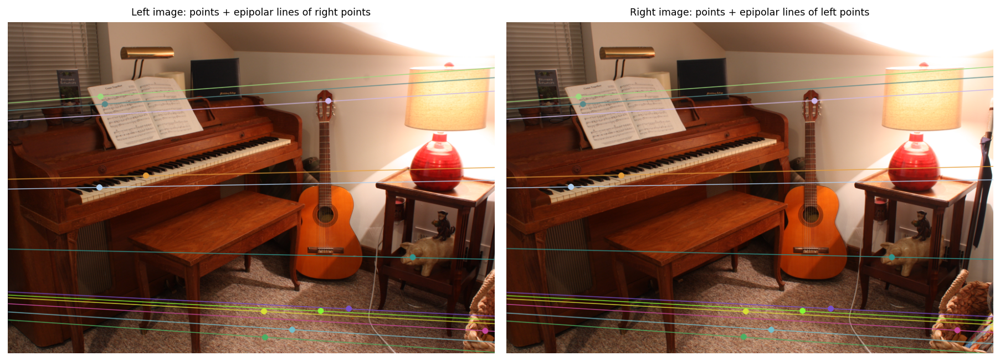

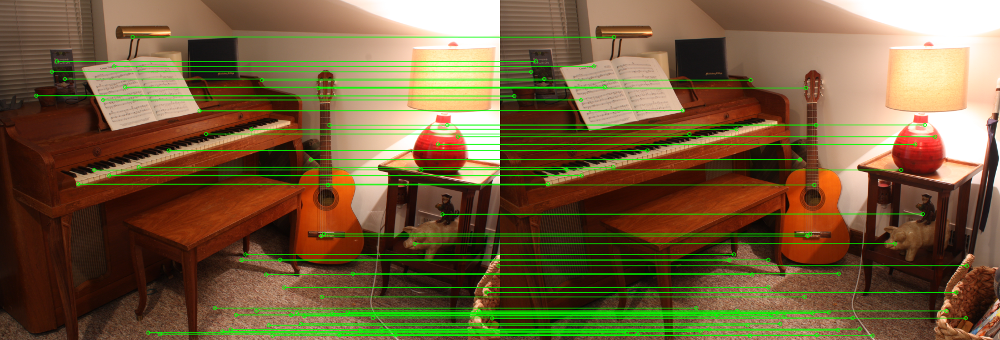

  disparity search: minDisparity=0, numDisparities=[48, 96]


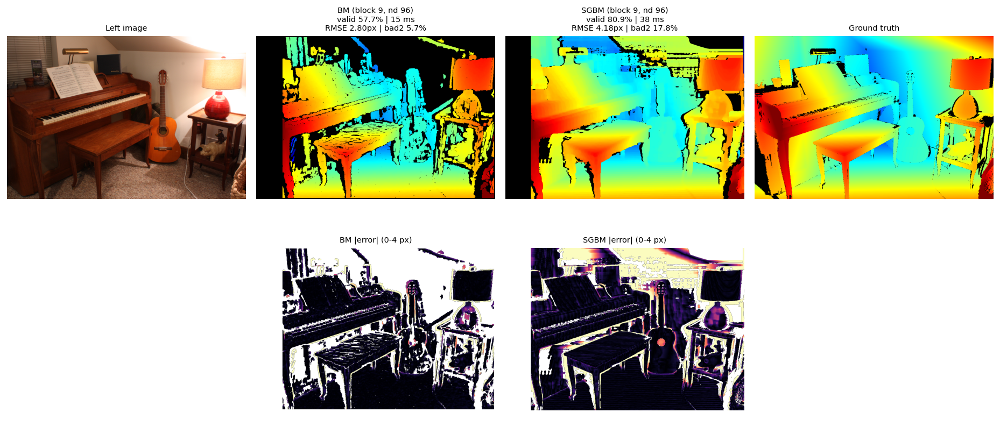

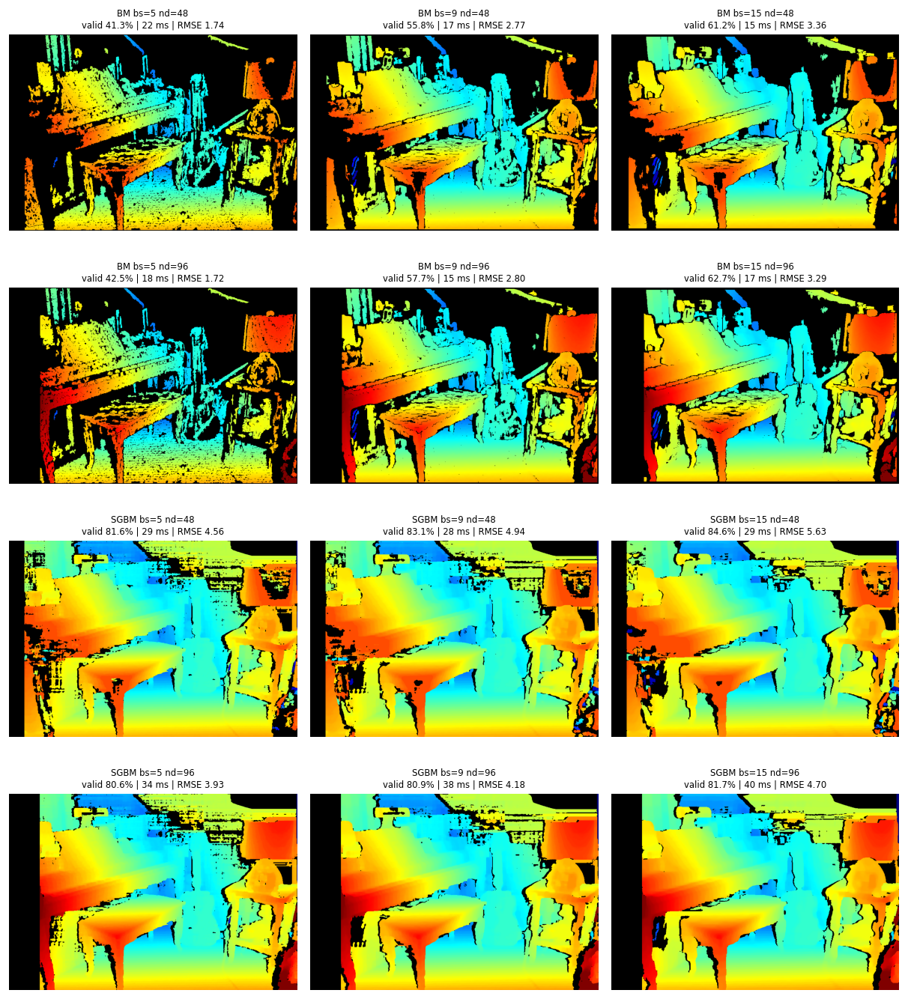

  point cloud: 433506 points | Z range kept [1.66, 2.88] m | Q vs pinhole formula max deviation 3.25e-07 m


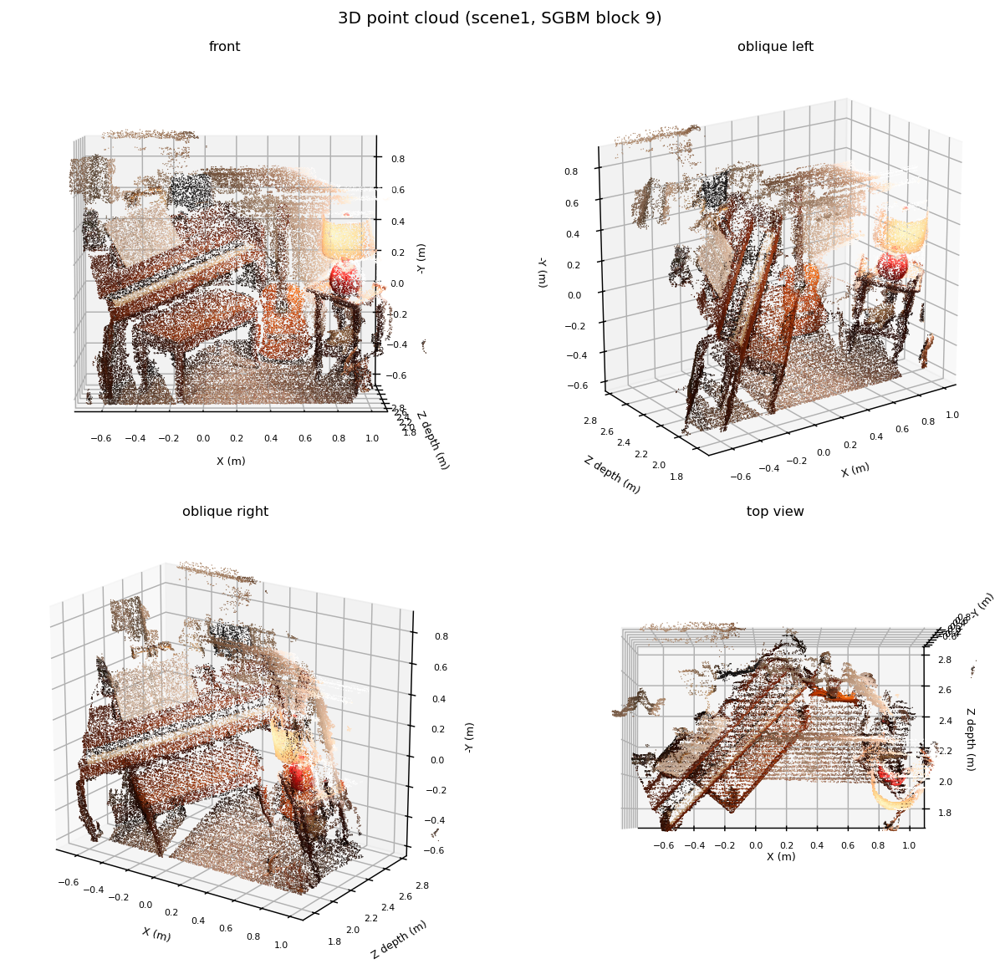

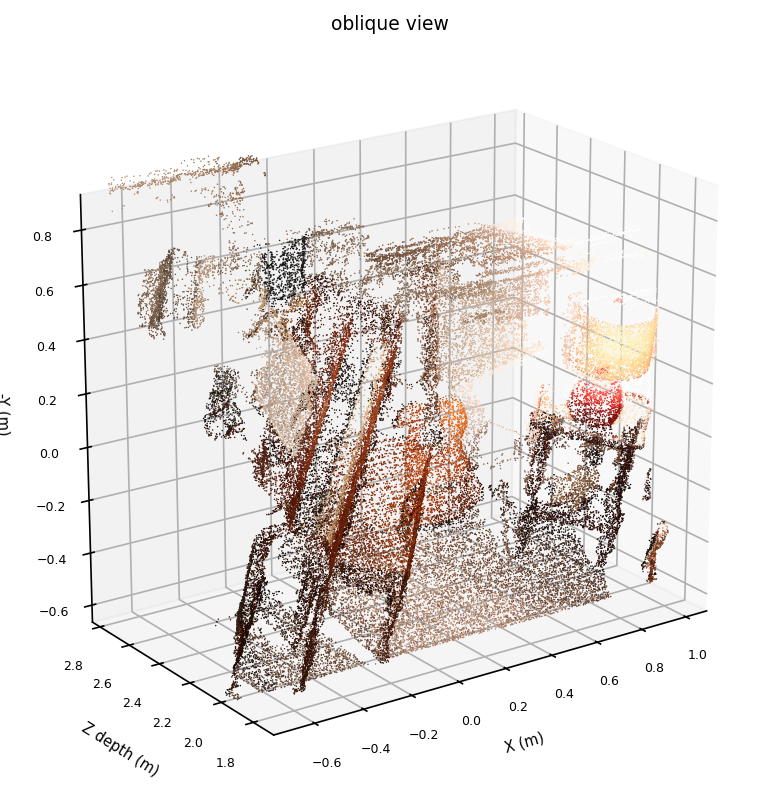


Disparity results:


,scene,method,blockSize,numDisparities,valid_pct,rmse_px,bad2_pct,coverage_pct,bad2_all_pct,runtime_ms
0,scene1,BM,5,48,41.31,1.74,3.49,42.37,59.11,21.59
1,scene1,BM,9,48,55.75,2.77,6.63,56.68,47.08,17.42
2,scene1,BM,15,48,61.22,3.36,9.54,62.10,43.82,14.84
3,scene1,BM,5,96,42.52,1.72,2.97,43.91,57.39,17.76
4,scene1,BM,9,96,57.74,2.80,5.66,59.05,44.29,15.49
5,scene1,BM,15,96,62.74,3.29,8.33,63.99,41.34,16.96
6,scene1,SGBM,5,48,81.61,4.56,20.27,82.55,34.19,29.23
7,scene1,SGBM,9,48,83.14,4.94,22.79,84.13,35.05,28.21
8,scene1,SGBM,15,48,84.61,5.63,25.39,85.63,36.12,28.92
9,scene1,SGBM,5,96,80.63,3.93,16.21,81.92,31.35,33.84



Done. Results saved in x:\Vision\results\partB


In [1]:
"""
INS3155 - Midterm Project - Part B: 3D Reconstruction from Stereo Images
-----------------------------------------------------------------------
Pipeline (per scene folder in data/partB/):
  1. Load left/right images (+ optional Middlebury calib.txt and GT disp0.pfm).
  2. SIFT + KNN + Lowe ratio test -> matches -> Fundamental matrix F with RANSAC.
     Draw epipolar lines on BOTH images; report mean epipolar / Sampson error (px).
  3. If the pair is not rectified (no calibration, large vertical offset):
     rectify with cv2.stereoRectifyUncalibrated.
  4. Dense disparity with Block Matching (BM) and Semi-Global Block Matching (SGBM)
     over a grid of blockSize x numDisparities.
     Metrics: valid disparity ratio, RMSE / bad-pixel rate (if GT), runtime (ms).
  5. Reproject the disparity map to a 3D point cloud (Q matrix), save .ply,
     and save multi-view screenshots (matplotlib - Open3D is NOT required).

Folder layout (one scene directly in data/partB/, or one sub-folder per scene):
    data/partB/im0.png  im1.png  [calib.txt]  [disp0.pfm]       (Middlebury style)
    data/partB/left.jpg right.jpg                                (own photos)

Run from the project root:
    python src/partB_stereo.py
    python src/partB_stereo.py --max-width 900 --repeats 3
    python src/partB_stereo.py --baseline 0.12 --focal-px 1500   (own photos, no calib)
If data/partB is empty a small synthetic scene (with GT) is generated as a demo.
"""
import argparse
import json
import re
import sys
import time
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib
IN_NOTEBOOK = "ipykernel" in sys.modules      # True when run in Jupyter / VS Code cell
if not IN_NOTEBOOK:
    matplotlib.use("Agg")                      # terminal: save files only
import matplotlib.pyplot as plt

# ----------------------------- Configuration -------------------------------
SEED = 42
MAX_WIDTH = 900                # images are resized so width <= this (calib/GT scaled too)
BLOCK_SIZES = [5, 9, 15]       # blockSize values (odd; BM needs >= 5)
MAIN_BLOCK = 9                 # blockSize used for the main BM-vs-SGBM figure / point cloud
RATIO = 0.75                   # Lowe's ratio
RANSAC_THRESH = 1.0            # px, RANSAC threshold for F
N_EPI_LINES = 12               # epipolar lines drawn per image
RECT_DY_THRESH = 1.0           # median |dy| (px) above which the pair is rectified by script
ASSUMED_FOCAL_RATIO = 0.8      # f_px = ratio * width when no calibration is given (ASSUMPTION)
DEFAULT_BASELINE_M = 0.10      # assumed baseline (m) when no calibration is given (ASSUMPTION)
MIN_DISP_3D = 1.0              # px: pixels with (d + doffs) below this are not reprojected
Z_PERCENTILES = (1, 98)        # default depth range kept in the point cloud (override: --zrange)
MAX_RENDER_POINTS = 60000      # points drawn per screenshot
MAX_PLY_POINTS = 400000        # points written to the .ply

LEFT_NAMES = ["im0.png", "im0.jpg", "left.png", "left.jpg", "imL.png", "imL.jpg",
              "view1.png", "view1.jpg"]
RIGHT_NAMES = ["im1.png", "im1.jpg", "right.png", "right.jpg", "imR.png", "imR.jpg",
               "view5.png", "view5.jpg"]
GT_NAMES = ["disp0.pfm", "disp0GT.pfm", "gt.pfm"]

try:
    ROOT = Path(__file__).resolve().parent.parent      # run as: python src/partB_stereo.py
except NameError:                                       # run inside Jupyter / VS Code cell
    ROOT = Path.cwd().parent if Path.cwd().name == "src" else Path.cwd()
DATA_DIR = ROOT / "data" / "partB"
OUT_DIR = ROOT / "results" / "partB"


# --------------------------------- I/O helpers ------------------------------
def first_existing(folder, names):
    for n in names:
        if (folder / n).exists():
            return folder / n
    return None


def read_pfm(path):
    """Read a PFM file (Middlebury GT disparity). Unknown pixels are +inf."""
    with open(path, "rb") as f:
        header = f.readline().decode().strip()
        color = header == "PF"
        w, h = map(int, f.readline().decode().split())
        scale = float(f.readline().decode().strip())
        data = np.fromfile(f, "<f4" if scale < 0 else ">f4")
    shape = (h, w, 3) if color else (h, w)
    return np.flipud(data.reshape(shape)).astype(np.float32)


def write_pfm(path, img):
    img = np.flipud(img.astype("<f4"))
    with open(path, "wb") as f:
        f.write(b"Pf\n%d %d\n-1.0\n" % (img.shape[1], img.shape[0]))
        f.write(img.tobytes())


def parse_calib(path):
    """Parse a Middlebury 2014 calib.txt."""
    txt = Path(path).read_text()
    cam0 = re.search(r"cam0=\[([^\]]+)\]", txt).group(1)
    K = np.array([[float(v) for v in row.split()] for row in cam0.split(";")])
    kv = dict(re.findall(r"^(\w+)=([\d.eE+-]+)\s*$", txt, re.M))
    return dict(f=K[0, 0], cx=K[0, 2], cy=K[1, 2], doffs=float(kv["doffs"]),
                B=float(kv["baseline"]), ndisp=int(float(kv.get("ndisp", 0))) or None,
                width=int(float(kv["width"])) if "width" in kv else None,
                unit_scale=0.001, assumed=False)          # Middlebury units: mm


def find_scenes():
    def has_pair(d):
        return first_existing(d, LEFT_NAMES) and first_existing(d, RIGHT_NAMES)
    if DATA_DIR.exists() and has_pair(DATA_DIR):
        return [("scene", DATA_DIR)]
    if DATA_DIR.exists():
        return [(p.name, p) for p in sorted(DATA_DIR.iterdir()) if p.is_dir() and has_pair(p)]
    return []


def make_demo_scene(folder):
    """Synthetic rectified pair with calib + GT (only used when data/partB is empty)."""
    from skimage import data
    folder.mkdir(parents=True, exist_ok=True)
    W, H = 640, 480
    tex = cv2.resize(data.coffee()[:, :, ::-1], (W, H), interpolation=cv2.INTER_AREA)
    yy, xx = np.mgrid[0:H, 0:W].astype(np.float32)
    d = 14 + 0.025 * yy                                    # slanted ground-like background
    d[(xx - 220) ** 2 / 110 ** 2 + (yy - 250) ** 2 / 120 ** 2 < 1] = 46   # near object
    d[(abs(xx - 470) < 70) & (abs(yy - 200) < 90)] = 30                  # mid object
    d = cv2.GaussianBlur(d, (0, 0), 1.0)
    right = cv2.remap(tex, xx + d, yy, cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
    gt = np.full((H, W), -1.0, np.float32)                 # left-view GT by forward mapping
    for y in range(H):
        xl = np.round(xx[y] + d[y]).astype(int)
        ok = (xl >= 0) & (xl < W)
        np.maximum.at(gt[y], xl[ok], d[y][ok])
    gt[gt < 0] = np.inf
    cv2.imwrite(str(folder / "im0.png"), tex)
    cv2.imwrite(str(folder / "im1.png"), right)
    write_pfm(folder / "disp0.pfm", gt)
    (folder / "calib.txt").write_text(
        f"cam0=[700 0 {W / 2}; 0 700 {H / 2}; 0 0 1]\ncam1=[700 0 {W / 2}; 0 700 {H / 2}; 0 0 1]\n"
        f"doffs=0\nbaseline=100\nwidth={W}\nheight={H}\nndisp=64\nisint=0\n")


def load_scene(folder, max_width, focal_px=None, baseline_m=None):
    lc = cv2.imread(str(first_existing(folder, LEFT_NAMES)), cv2.IMREAD_COLOR)
    rc = cv2.imread(str(first_existing(folder, RIGHT_NAMES)), cv2.IMREAD_COLOR)
    assert lc is not None and rc is not None, "cannot read images"
    H0, W0 = lc.shape[:2]
    s = min(1.0, max_width / W0)
    if s < 1.0:
        size = (int(round(W0 * s)), int(round(H0 * s)))
        lc = cv2.resize(lc, size, interpolation=cv2.INTER_AREA)
        rc = cv2.resize(rc, size, interpolation=cv2.INTER_AREA)
    H, W = lc.shape[:2]

    calib_p = folder / "calib.txt"
    if calib_p.exists():
        c = parse_calib(calib_p)
        cs = W / c["width"] if c.get("width") else s      # calib scale: used width / calib width
        if c.get("width") and c["width"] != W0:
            print(f"  [!] calib.txt width ({c['width']}) != image width ({W0}): "
                  f"calibration rescaled by {cs:.3f}")
        for k in ("f", "cx", "cy", "doffs"):
            c[k] *= cs
        if c["ndisp"]:
            c["ndisp"] = int(np.ceil(c["ndisp"] * cs))
        c["source"] = "calib.txt"
    else:
        c = dict(f=focal_px if focal_px else ASSUMED_FOCAL_RATIO * W, cx=W / 2, cy=H / 2,
                 doffs=0.0, B=baseline_m if baseline_m else DEFAULT_BASELINE_M, ndisp=None,
                 unit_scale=1.0, assumed=True, source="ASSUMED (no calibration)")

    gt = None
    gt_p = first_existing(folder, GT_NAMES)
    if gt_p is not None:
        g = read_pfm(gt_p)
        if g.ndim == 3:
            g = g[:, :, 0]
        gw = g.shape[1]
        if g.shape != (H, W):
            g = cv2.resize(g, (W, H), interpolation=cv2.INTER_NEAREST)
        gt = g * (W / gw)                      # disparities scale with image width
        gt[~np.isfinite(gt)] = np.nan
    return dict(lc=lc, rc=rc, gl=cv2.cvtColor(lc, cv2.COLOR_BGR2GRAY),
                gr=cv2.cvtColor(rc, cv2.COLOR_BGR2GRAY), calib=c, gt=gt, scale=s,
                orig_size=(W0, H0))


# ------------------------- Features, F and epipolar lines -------------------
def match_features(gl, gr):
    sift = cv2.SIFT_create()
    k1, d1 = sift.detectAndCompute(gl, None)
    k2, d2 = sift.detectAndCompute(gr, None)
    knn = cv2.BFMatcher(cv2.NORM_L2).knnMatch(d1, d2, k=2)
    good = [p[0] for p in knn if len(p) == 2 and p[0].distance < RATIO * p[1].distance]
    p1 = np.float32([k1[m.queryIdx].pt for m in good])
    p2 = np.float32([k2[m.trainIdx].pt for m in good])
    return k1, k2, good, p1, p2


def epipolar_errors(F, p1, p2):
    """Point-to-epipolar-line distance (both images) and Sampson distance, in px."""
    x1 = np.c_[p1, np.ones(len(p1))]
    x2 = np.c_[p2, np.ones(len(p2))]
    l2 = x1 @ F.T            # F x1   : epipolar lines in the right image
    l1 = x2 @ F              # F^T x2 : epipolar lines in the left image
    num = np.abs(np.sum(x2 * l2, axis=1))
    d_right = num / np.hypot(l2[:, 0], l2[:, 1])
    d_left = num / np.hypot(l1[:, 0], l1[:, 1])
    sampson = num / np.sqrt(l2[:, 0] ** 2 + l2[:, 1] ** 2 + l1[:, 0] ** 2 + l1[:, 1] ** 2)
    return 0.5 * (d_left + d_right), sampson


def draw_epilines(img, lines, pts, colors):
    out = img.copy()
    h, w = out.shape[:2]
    for (a, b, c), pt, col in zip(lines, pts, colors):
        if abs(b) > 1e-8:
            q0, q1 = (0, -c / b), (w, -(c + a * w) / b)
        else:
            q0, q1 = (-c / a, 0), (-c / a, h)
        q0 = tuple(int(np.clip(v, -1e5, 1e5)) for v in q0)
        q1 = tuple(int(np.clip(v, -1e5, 1e5)) for v in q1)
        cv2.line(out, q0, q1, col, 1, cv2.LINE_AA)
        cv2.circle(out, (int(pt[0]), int(pt[1])), 5, col, -1, cv2.LINE_AA)
    return out


# -------------------------------- Stereo matching ---------------------------
def make_matcher(method, bs, nd, min_d):
    if method == "BM":
        m = cv2.StereoBM_create(numDisparities=nd, blockSize=bs)
        m.setMinDisparity(min_d)
        m.setUniquenessRatio(10)
        m.setTextureThreshold(10)
        m.setSpeckleWindowSize(100)
        m.setSpeckleRange(2)
        m.setDisp12MaxDiff(1)
        return m
    return cv2.StereoSGBM_create(
        minDisparity=min_d, numDisparities=nd, blockSize=bs,
        P1=8 * bs * bs, P2=32 * bs * bs,            # single-channel input: cn = 1
        disp12MaxDiff=1, uniquenessRatio=10, speckleWindowSize=100, speckleRange=2,
        preFilterCap=63, mode=cv2.STEREO_SGBM_MODE_SGBM_3WAY)


def timed(fn, repeats):
    res = fn()                                   # warm-up (not timed)
    ts = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        res = fn()
        ts.append((time.perf_counter() - t0) * 1000)
    return res, float(np.median(ts))


def evaluate_disparity(disp, valid, gt, nd, min_d):
    out = dict(valid_pct=100 * valid.mean())
    core = np.zeros_like(valid)
    core[:, nd + max(min_d, 0):] = True          # columns where the whole search range fits
    out["valid_core_pct"] = 100 * valid[core].mean() if core.any() else np.nan
    keys = ("rmse_px", "bad1_pct", "bad2_pct", "coverage_pct", "bad2_all_pct")
    if gt is None:
        out.update({k: np.nan for k in keys})
        return out
    gv = np.isfinite(gt) & (gt > 0)
    both = valid & gv
    err = np.abs(disp[both] - gt[both])
    out["rmse_px"] = float(np.sqrt(np.mean(err ** 2))) if err.size else np.nan
    out["bad1_pct"] = 100 * float(np.mean(err > 1)) if err.size else np.nan
    out["bad2_pct"] = 100 * float(np.mean(err > 2)) if err.size else np.nan
    out["coverage_pct"] = 100 * both.sum() / max(gv.sum(), 1)
    bad_all = (gv & ~valid).sum() + (err > 2).sum()   # invalid pixels count as bad
    out["bad2_all_pct"] = 100 * bad_all / max(gv.sum(), 1)
    return out


# --------------------------------- 3D / plotting ----------------------------
def build_Q(c):
    """Disparity-to-depth matrix for a rectified, parallel pair (OpenCV convention):
       [X Y Z W]^T = Q [x y d 1]^T ;  W = (d + doffs) / B ;  Z = f / W = f B / (d + doffs)."""
    return np.array([[1, 0, 0, -c["cx"]],
                     [0, 1, 0, -c["cy"]],
                     [0, 0, 0, c["f"]],
                     [0, 0, 1.0 / c["B"], c["doffs"] / c["B"]]], dtype=np.float64)


def reproject(disp, valid, calib, left_bgr, zrange):
    Q = build_Q(calib)
    p3d = cv2.reprojectImageTo3D(disp.astype(np.float32), Q, handleMissingValues=False)
    ok = valid & (disp + calib["doffs"] > MIN_DISP_3D) & np.isfinite(p3d).all(axis=2)
    pts = p3d[ok].astype(np.float64) * calib["unit_scale"]            # -> metres
    rgb = left_bgr[ok][:, ::-1]
    # consistency check with the closed-form pinhole equations
    ys, xs = np.nonzero(ok)
    Zc = calib["f"] * calib["B"] / (disp[ok] + calib["doffs"]) * calib["unit_scale"]
    Xc = (xs - calib["cx"]) * Zc / calib["f"]
    max_dev = float(np.max(np.abs(np.c_[Xc, Zc] - pts[:, [0, 2]])))
    if zrange is None:
        lo, hi = np.percentile(pts[:, 2], Z_PERCENTILES)
    else:
        lo, hi = zrange
    keep = (pts[:, 2] >= lo) & (pts[:, 2] <= hi)
    return pts[keep], rgb[keep], Q, (float(lo), float(hi)), max_dev


def write_ply(path, pts, rgb):
    """Binary PLY. Stored in OpenGL-style camera frame (Y up, looking toward -Z)."""
    n = len(pts)
    arr = np.empty(n, dtype=[("x", "<f4"), ("y", "<f4"), ("z", "<f4"),
                             ("r", "u1"), ("g", "u1"), ("b", "u1")])
    arr["x"], arr["y"], arr["z"] = pts[:, 0], -pts[:, 1], -pts[:, 2]
    arr["r"], arr["g"], arr["b"] = rgb[:, 0], rgb[:, 1], rgb[:, 2]
    header = ("ply\nformat binary_little_endian 1.0\n"
              f"element vertex {n}\nproperty float x\nproperty float y\nproperty float z\n"
              "property uchar red\nproperty uchar green\nproperty uchar blue\nend_header\n")
    with open(path, "wb") as f:
        f.write(header.encode())
        f.write(arr.tobytes())


def show_saved(path):
    """In a notebook, display an image file that was written to disk."""
    if IN_NOTEBOOK:
        try:
            from IPython.display import Image, display
            display(Image(filename=str(path)))
        except ImportError:
            pass


def save_fig(fig, path, dpi=130):
    fig.savefig(path, dpi=dpi, bbox_inches="tight")
    plt.close(fig)
    show_saved(path)


def colorize(disp, valid, vmin, vmax):
    norm = np.clip((disp - vmin) / (vmax - vmin + 1e-9), 0, 1)
    col = cv2.applyColorMap((norm * 255).astype(np.uint8), cv2.COLORMAP_JET)
    col[~valid] = 0
    return col


def show_bgr(ax, img, title, fs=8):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(title, fontsize=fs)
    ax.axis("off")


def render_cloud(ax, pts, rgb, rng, elev, azim, title):
    n = len(pts)
    sel = rng.choice(n, MAX_RENDER_POINTS, replace=False) if n > MAX_RENDER_POINTS else slice(None)
    P, C = pts[sel], rgb[sel] / 255.0
    x, y, z = P[:, 0], P[:, 2], -P[:, 1]              # X right, Z depth, -Y up (proper rotation)
    ax.scatter(x, y, z, c=C, s=0.5, linewidths=0, depthshade=False, rasterized=True)
    lim = [np.percentile(v, [0.5, 99.5]) for v in (x, y, z)]
    ax.set_xlim(*lim[0]); ax.set_ylim(*lim[1]); ax.set_zlim(*lim[2])
    r = np.array([l[1] - l[0] for l in lim])
    ax.set_box_aspect(np.maximum(r / r.max(), 0.15))
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlabel("X (m)", fontsize=7); ax.set_ylabel("Z depth (m)", fontsize=7)
    ax.set_zlabel("-Y (m)", fontsize=7)
    ax.tick_params(labelsize=6)
    ax.set_title(title, fontsize=9)


# ------------------------------------ Main ----------------------------------
def process_scene(name, sc, args, out_dir):
    rng = np.random.default_rng(SEED)
    out_dir.mkdir(parents=True, exist_ok=True)
    lc, rc, gl, gr, calib, gt = sc["lc"], sc["rc"], sc["gl"], sc["gr"], sc["calib"], sc["gt"]
    H, W = gl.shape
    print(f"  size {W}x{H} (scale {sc['scale']:.3f}) | calibration: {calib['source']}"
          f" | GT: {'yes' if gt is not None else 'no'}")
    if calib["assumed"]:
        print("  [!] No calib.txt: focal length and baseline are ASSUMED -> 3D scale is only "
              "approximate (relative geometry is still meaningful).")

    # ---- 1) features -> F (RANSAC) -> epipolar lines --------------------------------
    t0 = time.perf_counter()
    k1, k2, good, p1, p2 = match_features(gl, gr)
    assert len(good) >= 8, "not enough matches to estimate F"
    F, mask = cv2.findFundamentalMat(p1, p2, cv2.FM_RANSAC, RANSAC_THRESH, 0.999, 5000)
    F = F[:3]
    t_ms = (time.perf_counter() - t0) * 1000
    inl = mask.ravel().astype(bool)
    q1, q2 = p1[inl], p2[inl]
    epi_in, sam_in = epipolar_errors(F, q1, q2)
    epi_all, sam_all = epipolar_errors(F, p1, p2)
    dy = float(np.median(np.abs(q1[:, 1] - q2[:, 1])))
    print(f"  keypoints {len(k1)}/{len(k2)} | matches {len(good)} | inliers {inl.sum()} "
          f"({100 * inl.mean():.1f}%) | mean epipolar dist {epi_in.mean():.3f}px "
          f"| mean Sampson {sam_in.mean():.3f}px | median |dy| {dy:.2f}px")

    sel = np.sort(rng.choice(len(q1), min(N_EPI_LINES, len(q1)), replace=False))
    cols = [tuple(int(v) for v in rng.integers(40, 255, 3)) for _ in sel]
    lines_r = cv2.computeCorrespondEpilines(q1[sel].reshape(-1, 1, 2), 1, F).reshape(-1, 3)
    lines_l = cv2.computeCorrespondEpilines(q2[sel].reshape(-1, 1, 2), 2, F).reshape(-1, 3)
    img_l = draw_epilines(lc, lines_l, q1[sel], cols)
    img_r = draw_epilines(rc, lines_r, q2[sel], cols)
    fig, ax = plt.subplots(1, 2, figsize=(13, 5.2))
    show_bgr(ax[0], img_l, "Left image: points + epipolar lines of right points", 9)
    show_bgr(ax[1], img_r, "Right image: points + epipolar lines of left points", 9)
    fig.tight_layout()
    save_fig(fig, out_dir / "epipolar_lines.png", 140)

    sub = np.flatnonzero(inl)
    sub = sub[np.linspace(0, len(sub) - 1, min(60, len(sub))).astype(int)]
    dm = [good[i] for i in sub]
    vis = cv2.drawMatches(lc, k1, rc, k2, dm, None, matchColor=(0, 255, 0),
                          flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    cv2.imwrite(str(out_dir / "matches_inliers.png"), vis)
    show_saved(out_dir / "matches_inliers.png")

    # ---- 2) rectify if needed -------------------------------------------------------
    rectified = False
    d1, d2 = q1, q2                              # match coordinates used for the disparity range
    if calib["assumed"] and dy > RECT_DY_THRESH:
        ok, H1, H2 = cv2.stereoRectifyUncalibrated(q1, q2, F, (W, H))
        if ok:
            lc, rc = cv2.warpPerspective(lc, H1, (W, H)), cv2.warpPerspective(rc, H2, (W, H))
            gl, gr = cv2.cvtColor(lc, cv2.COLOR_BGR2GRAY), cv2.cvtColor(rc, cv2.COLOR_BGR2GRAY)
            gt, rectified = None, True
            d1 = cv2.perspectiveTransform(q1.reshape(-1, 1, 2), H1).reshape(-1, 2)
            d2 = cv2.perspectiveTransform(q2.reshape(-1, 1, 2), H2).reshape(-1, 2)
            res_dy = float(np.median(np.abs(d1[:, 1] - d2[:, 1])))
            cv2.imwrite(str(out_dir / "rectified_left.png"), lc)
            cv2.imwrite(str(out_dir / "rectified_right.png"), rc)
            both = np.hstack([lc, rc])
            for y in range(0, H, 40):
                cv2.line(both, (0, y), (2 * W, y), (0, 255, 0), 1)
            cv2.imwrite(str(out_dir / "rectified_pair_with_lines.png"), both)
            show_saved(out_dir / "rectified_pair_with_lines.png")
            print(f"  pair was NOT rectified -> rectified with stereoRectifyUncalibrated "
                  f"(median |dy| {dy:.2f} -> {res_dy:.2f} px; GT not usable after warping)")

    # ---- 3) disparity range -----------------------------------------------------------
    if calib["ndisp"]:
        min_d, nd = 0, int(np.ceil(calib["ndisp"] / 16) * 16)
    else:
        dxs = d1[:, 0] - d2[:, 0]
        lo, hi = np.percentile(dxs, [1, 99])
        min_d = int(np.floor(min(0.0, lo) / 16) * 16)
        nd = int(np.ceil((hi - min_d) / 16) * 16) + 16
    nd = int(max(16, min(nd, ((W - max(BLOCK_SIZES) - 1) // 16) * 16)))
    nd_half = int(max(16, round(nd / 2 / 16) * 16))
    nds = sorted({nd_half, nd})
    print(f"  disparity search: minDisparity={min_d}, numDisparities={nds}")

    # ---- 4) BM vs SGBM grid -----------------------------------------------------------
    results, rows = {}, []
    for method in ("BM", "SGBM"):
        for n_d in nds:
            for bs in BLOCK_SIZES:
                m = make_matcher(method, bs, n_d, min_d)
                raw, t = timed(lambda: m.compute(gl, gr), args.repeats)
                disp = raw.astype(np.float32) / 16.0
                valid = raw > (min_d - 1) * 16
                met = evaluate_disparity(disp, valid, gt, n_d, min_d)
                rows.append(dict(scene=name, method=method, blockSize=bs, numDisparities=n_d,
                                 minDisparity=min_d, **met, runtime_ms=t))
                results[(method, bs, n_d)] = (disp, valid, met, t)
    df = pd.DataFrame(rows)
    df.to_csv(out_dir / "metrics_disparity.csv", index=False, float_format="%.4f")

    main_bs = MAIN_BLOCK if MAIN_BLOCK in BLOCK_SIZES else BLOCK_SIZES[0]
    ref = results[("SGBM", main_bs, nd)]
    if gt is not None and np.isfinite(gt).any():
        vmax = float(np.nanpercentile(gt[np.isfinite(gt)], 99))
    else:
        vmax = float(np.percentile(ref[0][ref[1]], 99)) if ref[1].any() else nd
    vmin = float(min_d)

    # main comparison figure
    items = [("Left image", lc)]
    for method in ("BM", "SGBM"):
        disp, valid, met, t = results[(method, main_bs, nd)]
        ttl = f"{method} (block {main_bs}, nd {nd})\nvalid {met['valid_pct']:.1f}% | {t:.0f} ms"
        if gt is not None:
            ttl += f"\nRMSE {met['rmse_px']:.2f}px | bad2 {met['bad2_pct']:.1f}%"
        items.append((ttl, colorize(disp, valid, vmin, vmax)))
    if gt is not None:
        g = np.nan_to_num(gt, nan=0.0)
        items.append(("Ground truth", colorize(g, np.isfinite(gt) & (gt > 0), vmin, vmax)))
    nrow = 2 if gt is not None else 1
    fig, axes = plt.subplots(nrow, len(items), figsize=(3.6 * len(items), 3.3 * nrow),
                             squeeze=False)
    for j, (t, im) in enumerate(items):
        show_bgr(axes[0, j], im, t)
    if gt is not None:
        axes[1, 0].axis("off")
        gv = np.isfinite(gt) & (gt > 0)
        for j, method in enumerate(("BM", "SGBM")):
            disp, valid, _, _ = results[(method, main_bs, nd)]
            e = np.where(valid & gv, np.abs(disp - np.nan_to_num(gt)), np.nan)
            axes[1, j + 1].imshow(e, cmap="magma", vmin=0, vmax=4)
            axes[1, j + 1].set_title(f"{method} |error| (0-4 px)", fontsize=8)
            axes[1, j + 1].axis("off")
        axes[1, 3].axis("off")
    fig.tight_layout()
    save_fig(fig, out_dir / "disparity_bm_vs_sgbm.png", 130)

    # parameter-sweep figure
    row_keys = [(m, n_d) for m in ("BM", "SGBM") for n_d in nds]
    fig, axes = plt.subplots(len(row_keys), len(BLOCK_SIZES),
                             figsize=(3.4 * len(BLOCK_SIZES), 2.9 * len(row_keys)), squeeze=False)
    for i, (m, n_d) in enumerate(row_keys):
        for j, bs in enumerate(BLOCK_SIZES):
            disp, valid, met, t = results[(m, bs, n_d)]
            ttl = f"{m} bs={bs} nd={n_d}\nvalid {met['valid_pct']:.1f}% | {t:.0f} ms"
            if gt is not None:
                ttl += f" | RMSE {met['rmse_px']:.2f}"
            show_bgr(axes[i, j], colorize(disp, valid, vmin, vmax), ttl, 7)
    fig.tight_layout()
    save_fig(fig, out_dir / "disparity_param_sweep.png", 120)

    # ---- 5) 3D point cloud ------------------------------------------------------------
    disp, valid, _, _ = ref
    pts, rgb, Q, (zlo, zhi), dev = reproject(disp, valid, calib, lc, args.zrange)
    print(f"  point cloud: {len(pts)} points | Z range kept [{zlo:.2f}, {zhi:.2f}] m | "
          f"Q vs pinhole formula max deviation {dev:.2e} m")
    if len(pts) > 100:
        keep = rng.choice(len(pts), min(len(pts), MAX_PLY_POINTS), replace=False)
        write_ply(out_dir / "pointcloud.ply", pts[keep], rgb[keep])
        fig = plt.figure(figsize=(11, 9))
        views = [("front", 5, -90), ("oblique left", 20, -125),
                 ("oblique right", 20, -55), ("top view", 88, -90)]
        for i, (t, el, az) in enumerate(views):
            ax = fig.add_subplot(2, 2, i + 1, projection="3d")
            render_cloud(ax, pts, rgb, rng, el, az, t)
        fig.suptitle(f"3D point cloud ({name}, SGBM block {main_bs})", fontsize=11)
        fig.tight_layout()
        save_fig(fig, out_dir / "pointcloud_views.png", 130)
        fig = plt.figure(figsize=(8, 6.5))
        ax = fig.add_subplot(111, projection="3d")
        render_cloud(ax, pts, rgb, rng, 20, -125, "oblique view")
        save_fig(fig, out_dir / "pointcloud_oblique.png", 150)

    # ---- 6) tables --------------------------------------------------------------------
    epi = dict(scene=name, keypoints_left=len(k1), keypoints_right=len(k2),
               initial_matches=len(good), inliers=int(inl.sum()),
               inlier_ratio_pct=100 * inl.mean(), mean_epipolar_dist_px=epi_in.mean(),
               median_epipolar_dist_px=np.median(epi_in), mean_sampson_px=sam_in.mean(),
               median_sampson_px=np.median(sam_in), mean_sampson_all_matches_px=sam_all.mean(),
               median_abs_dy_px=dy, rectified_by_script=rectified,
               ransac_thresh_px=RANSAC_THRESH, match_plus_F_time_ms=t_ms)
    pd.DataFrame([epi]).to_csv(out_dir / "metrics_epipolar.csv", index=False, float_format="%.4f")
    info = dict(scene=name, image_size=[W, H], scale=sc["scale"], calibration=calib,
                F=F.tolist(), Q=Q.tolist(), numDisparities=nds, minDisparity=min_d,
                z_range_m=[zlo, zhi], n_points=int(len(pts)), rectified_by_script=rectified)
    (out_dir / "calibration_used.json").write_text(json.dumps(info, indent=2))
    return df, epi


def main():
    ap = argparse.ArgumentParser(allow_abbrev=False)
    ap.add_argument("--max-width", type=int, default=MAX_WIDTH)
    ap.add_argument("--repeats", type=int, default=3, help="timing repetitions (median)")
    ap.add_argument("--baseline", type=float, default=None, help="metres (no calib.txt)")
    ap.add_argument("--focal-px", type=float, default=None, help="pixels (no calib.txt)")
    ap.add_argument("--zrange", type=float, nargs=2, default=None, metavar=("ZMIN", "ZMAX"),
                    help="depth range (m) kept in the point cloud (default: 1-98 percentile)")
    args, _ = ap.parse_known_args()                       # ignore args injected by Jupyter

    OUT_DIR.mkdir(parents=True, exist_ok=True)
    scenes = find_scenes()
    if not scenes:
        print("[!] No stereo pair in data/partB -> generating a SYNTHETIC demo scene.")
        demo = OUT_DIR / "_demo_input"
        make_demo_scene(demo)
        scenes = [("demo_synthetic", demo)]
    all_disp, all_epi = [], []
    for name, folder in scenes:
        print(f"\n=== Scene: {name} ===")
        sc = load_scene(folder, args.max_width, args.focal_px, args.baseline)
        df, epi = process_scene(name, sc, args, OUT_DIR / name)
        all_disp.append(df)
        all_epi.append(epi)
    pd.concat(all_disp).to_csv(OUT_DIR / "metrics_partB_disparity.csv", index=False,
                               float_format="%.4f")
    pd.DataFrame(all_epi).to_csv(OUT_DIR / "metrics_partB_epipolar.csv", index=False,
                                 float_format="%.4f")
    cols = ["scene", "method", "blockSize", "numDisparities", "valid_pct", "rmse_px",
            "bad2_pct", "coverage_pct", "bad2_all_pct", "runtime_ms"]
    table = pd.concat(all_disp)[cols].round(2).reset_index(drop=True)
    print("\nDisparity results:")
    try:
        if not IN_NOTEBOOK:
            raise ImportError
        from IPython.display import display
        display(table)
    except ImportError:
        print(table.to_string(index=False))
    print(f"\nDone. Results saved in {OUT_DIR}")


if __name__ == "__main__":
    main()